In [2]:
%pip install matplotlib seaborn pandas numpy

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("DataSets/FantasyData.csv")

# Missing counts mean "did not do that", so 0 is fine (NOT for rate columns like Ctch% or Y/Tgt)
count_cols = ['G', 'GS', 'RushAtt', 'RushYds', 'RushTD', 'Rush1D',
              'Cmp', 'PassAtt', 'PassYds', 'PassTD', 'Int', 'Pass1D',
              'Tgt', 'Rec', 'ReceiveYds', 'ReceiveTD', 'Receive1D']
df[count_cols] = df[count_cols].fillna(0)

# Only the four fantasy-relevant positions
df = df[df['Pos'].isin(['QB', 'RB', 'WR', 'TE'])].copy()

# One row per player-season (traded players can have a combined row plus per-team rows)
before = len(df)
df = df.sort_values('G', ascending=False).drop_duplicates(['Player', 'year']).sort_index()
print(f"Dropped {before - len(df)} duplicate player-season rows; {len(df)} rows remain.")
print(df.groupby(['year', 'Pos']).size().unstack())

  Using cached matplotlib-3.11.2-cp314-cp314-macosx_11_0_arm64.whl.metadata (80 kB)
  Using cached seaborn-0.13.2-py3-none-any.whl.metadata (5.4 kB)
  Using cached contourpy-1.4.0-cp314-cp314-macosx_11_0_arm64.whl.metadata (3.8 kB)
  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
  Using cached fonttools-4.68.0-cp314-cp314-macosx_10_15_universal2.whl.metadata (139 kB)
  Using cached kiwisolver-1.5.1-cp314-cp314-macosx_11_0_arm64.whl.metadata (5.2 kB)
  Using cached pillow-13.0.0-cp314-cp314-macosx_11_0_arm64.whl.metadata (9.1 kB)
  Using cached pyparsing-3.3.3-py3-none-any.whl.metadata (5.9 kB)
Using cached matplotlib-3.11.2-cp314-cp314-macosx_11_0_arm64.whl (9.3 MB)
Using cached seaborn-0.13.2-py3-none-any.whl (294 kB)
Using cached contourpy-1.4.0-cp314-cp314-macosx_11_0_arm64.whl (283 kB)
Using cached cycler-0.12.1-py3-none-any.whl (8.3 kB)
Using cached fonttools-4.68.0-cp314-cp314-macosx_10_15_universal2.whl (3.1 MB)
Using cached kiwisolver-1.5.1-cp314-cp314-macosx_11

In [3]:
g0 = df['G'].replace(0, np.nan)
df['Plays'] = df['RushAtt'] + df['Rec'] + df['PassAtt']
df['PlaysPG'] = df['Plays'] / g0
df['TgtPG'] = df['Tgt'] / g0
df['RushAttPG'] = df['RushAtt'] / g0
df['PassAttPG'] = df['PassAtt'] / g0

MIN_PLAYS = {'QB': 200, 'RB': 100, 'WR': 40, 'TE': 30}
df['MinPlays'] = df['Pos'].map(MIN_PLAYS)
qual = df[df['Plays'] >= df['MinPlays']].copy()
print(f"{len(qual)} qualified player-seasons (of {len(df)})")

390 qualified player-seasons (of 1111)


/Users/tiagocaravia-perry/coding-projects/MDSTFootballProject/.venv/lib/python3.14/site-packages/numpy/lib/_function_base_impl.py:3037: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
/Users/tiagocaravia-perry/coding-projects/MDSTFootballProject/.venv/lib/python3.14/site-packages/numpy/lib/_function_base_impl.py:3038: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


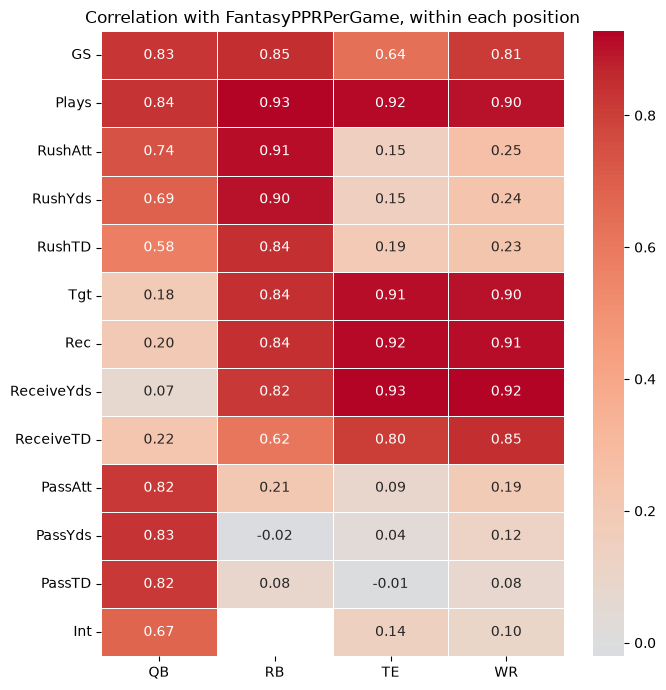

In [4]:
features = ['GS', 'Plays', 'RushAtt', 'RushYds', 'RushTD', 'Tgt', 'Rec', 'ReceiveYds', 'ReceiveTD',
            'PassAtt', 'PassYds', 'PassTD', 'Int']
by_pos = pd.DataFrame({
    pos: g[features].corrwith(g['FantasyPPRPerGame']) for pos, g in df.groupby('Pos')
})
plt.figure(figsize=(7, 7))
sns.heatmap(by_pos, annot=True, fmt='.2f', cmap='coolwarm', center=0, linewidths=.5)
plt.title('Correlation with FantasyPPRPerGame, within each position')
plt.tight_layout()
plt.show()

In [5]:
def cv_r2(X, y, k=5, reps=30, seed=0):
    X = np.asarray(X, float)
    if X.ndim == 1:
        X = X[:, None]
    y = np.asarray(y, float)
    n = len(y)
    rng = np.random.default_rng(seed)
    scores = []
    for _ in range(reps):
        idx = rng.permutation(n)
        pred = np.empty(n)
        for f in np.array_split(idx, k):
            tr = np.setdiff1d(idx, f)
            A = np.column_stack([np.ones(len(tr)), X[tr]])
            beta = np.linalg.lstsq(A, y[tr], rcond=None)[0]
            pred[f] = np.column_stack([np.ones(len(f)), X[f]]) @ beta
        scores.append(1 - ((y - pred) ** 2).sum() / ((y - y.mean()) ** 2).sum())
    return float(np.mean(scores))


years = sorted(df['year'].unique())
y0, y1 = years[0], years[-1]
pos_map = df.drop_duplicates('Player').set_index('Player')['Pos']

vals = ['PlaysPG', 'TgtPG', 'RushAttPG', 'PassAttPG', 'FantasyPPRPerGame']
nxt = qual.pivot_table(index='Player', columns='year', values=vals).dropna()
nxt['Pos'] = pos_map.reindex(nxt.index)

rows = []
for pos, g in nxt.groupby('Pos'):
    if len(g) < 20:
        continue
    y = g[('FantasyPPRPerGame', y1)]
    last_ppr = g[('FantasyPPRPerGame', y0)]
    usage = np.column_stack([g[(c, y0)] for c in ['PlaysPG', 'TgtPG', 'RushAttPG', 'PassAttPG']])
    rows.append({
        'Pos': pos,
        'n': len(g),
        'last PPR/G only': cv_r2(last_ppr, y),
        'last usage only': cv_r2(usage, y),
        'last PPR/G + usage': cv_r2(np.column_stack([last_ppr, usage]), y),
    })
print(f"Out-of-sample R^2 predicting {y1} PPR/G from {y0} features")
pd.DataFrame(rows).set_index('Pos').round(3)

Out-of-sample R^2 predicting 2025 PPR/G from 2024 features


,n,last PPR/G only,last usage only,last PPR/G + usage
Pos,,,,
QB,29,0.016,-0.009,-0.054
RB,36,0.350,0.039,0.154
TE,28,-0.105,-6.486,-5.696
WR,44,0.345,0.263,0.244


In [13]:
usage_cols = {
    'QB': ['PassAttPG', 'RushAttPG'],
    'RB': ['RushAttPG', 'TgtPG'],
    'WR': ['TgtPG'],
    'TE': ['TgtPG'],
}

rows = []
for pos, g in nxt.groupby('Pos'):
    if len(g) < 20:
        continue
    y = g[('FantasyPPRPerGame', y1)]
    last_ppr = g[('FantasyPPRPerGame', y0)]
    usage = np.column_stack([g[(c, y0)] for c in usage_cols[pos]])
    rows.append({
        'Pos': pos,
        'n': len(g),
        'last PPR/G only': cv_r2(last_ppr, y),
        'last usage only': cv_r2(usage, y),
        'last PPR/G + usage': cv_r2(np.column_stack([last_ppr, usage]), y),
    })
pd.DataFrame(rows).set_index('Pos').round(3)

,n,last PPR/G only,last usage only,last PPR/G + usage
Pos,,,,
QB,29,0.016,-0.034,-0.060
RB,36,0.350,0.108,0.227
TE,28,-0.105,-0.064,-0.200
WR,44,0.345,0.317,0.337


/Users/tiagocaravia-perry/coding-projects/MDSTFootballProject/.venv/lib/python3.14/site-packages/seaborn/regression.py:598: UserWarning: sharex is deprecated from the `lmplot` function signature. Please update your code to pass it using `facet_kws`.
  warnings.warn(msg, UserWarning)
/Users/tiagocaravia-perry/coding-projects/MDSTFootballProject/.venv/lib/python3.14/site-packages/seaborn/regression.py:598: UserWarning: sharey is deprecated from the `lmplot` function signature. Please update your code to pass it using `facet_kws`.
  warnings.warn(msg, UserWarning)


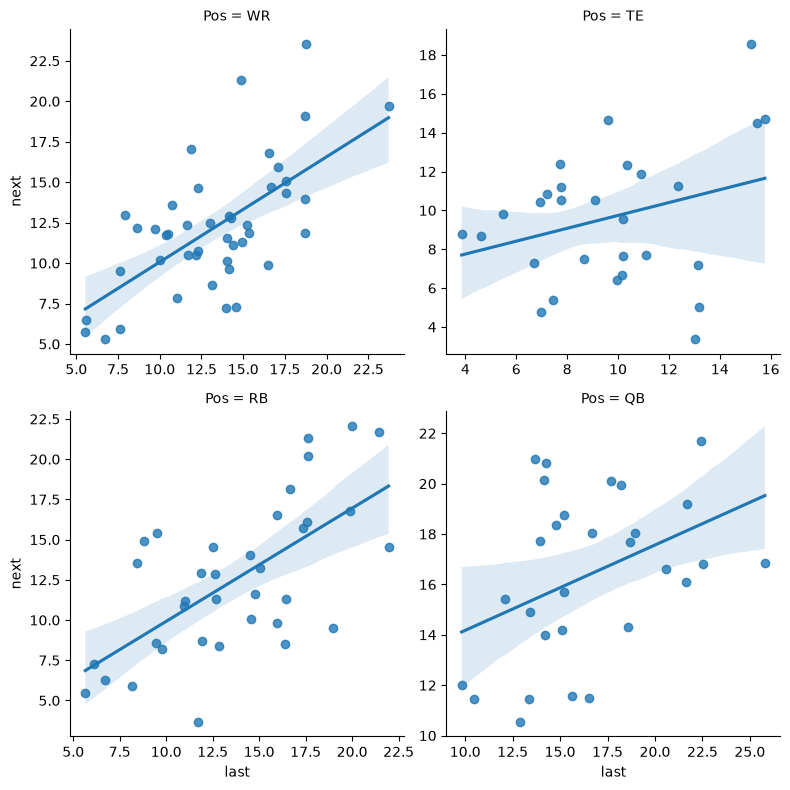

In [6]:
plot_df = pd.DataFrame({
    'last': nxt[('FantasyPPRPerGame', y0)],
    'next': nxt[('FantasyPPRPerGame', y1)],
    'Pos': nxt['Pos'],
})
sns.lmplot(data=plot_df, x='last', y='next', col='Pos', col_wrap=2, height=4, sharex=False, sharey=False)
plt.show()

In [7]:
age_tbl = (df.groupby(['Pos', 'Age'])['FantasyPPRPerGame']
             .agg(['mean', 'count'])
             .query('count >= 5')
             .round(2))
age_tbl

mean  count
Pos Age               
QB  22.0  13.58      5
    23.0  10.47      9
    24.0  10.07     15
    25.0   7.80     20
    26.0  10.58     19
    27.0  11.57     16
    28.0  11.35     12
    29.0   8.58     15
    30.0   8.45      9
    31.0  11.04      7
    32.0   6.84      6
    33.0  11.12      6
RB  21.0   3.13      9
    22.0   6.87     21
    23.0   7.05     31
    24.0   6.08     35
    25.0   6.03     50
    26.0   6.37     45
    27.0   6.90     27
    28.0   6.31     17
    29.0   6.80     17
    30.0   8.92     10
TE  22.0   4.89      9
    23.0   4.55     15
    24.0   3.18     31
    25.0   4.00     39
    26.0   3.41     37
    27.0   2.81     23
    28.0   3.74     18
    29.0   5.57     17
    30.0   4.34     16
    31.0   4.10     14
    32.0   4.47      7
WR  21.0   9.03      5
    22.0   7.29     23
    23.0   5.75     61
    24.0   5.91     70
    25.0   6.76     61
    26.0   5.19     45
    27.0   4.63     46
    28.0   5.55     38
    29.0   4.49     31
    30.0   5.07     23
    31.0   6.65     17
    32.0   6.75     16

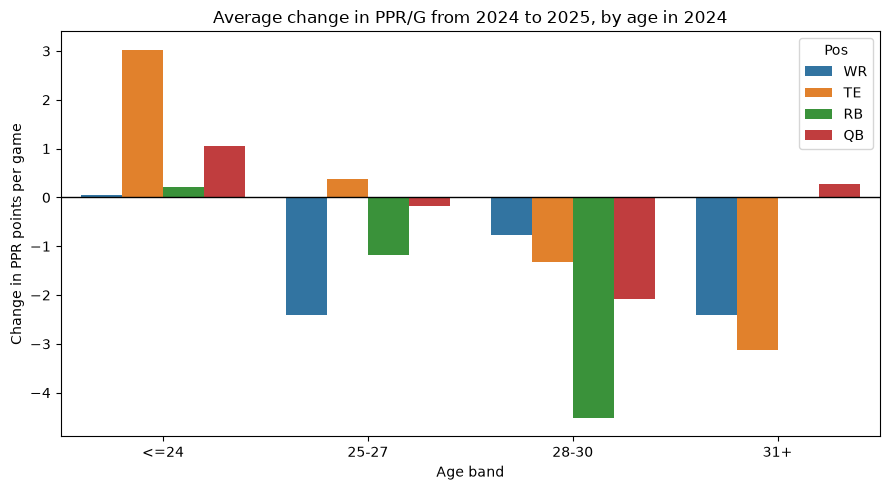

Age band,<=24,25-27,28-30,31+
Pos,,,,
QB,7,11,5,6
RB,12,19,5,0
TE,6,10,8,4
WR,21,14,4,5


In [9]:
age0 = qual[qual['year'] == y0].set_index('Player')['Age']

change = pd.DataFrame({
    'Pos': nxt['Pos'],
    'Age': age0.reindex(nxt.index),
    'PPR/G change': nxt[('FantasyPPRPerGame', y1)] - nxt[('FantasyPPRPerGame', y0)],
}).dropna()

bands = [0, 24, 27, 30, 50]
labels = ['<=24', '25-27', '28-30', '31+']
change['Age band'] = pd.cut(change['Age'], bins=bands, labels=labels)

plt.figure(figsize=(9, 5))
sns.barplot(data=change, x='Age band', y='PPR/G change', hue='Pos', errorbar=None)
plt.axhline(0, color='black', linewidth=1)
plt.title(f'Average change in PPR/G from {y0} to {y1}, by age in {y0}')
plt.ylabel('Change in PPR points per game')
plt.tight_layout()
plt.show()

# Sample sizes behind each bar
change.groupby(['Pos', 'Age band'], observed=True).size().unstack(fill_value=0)

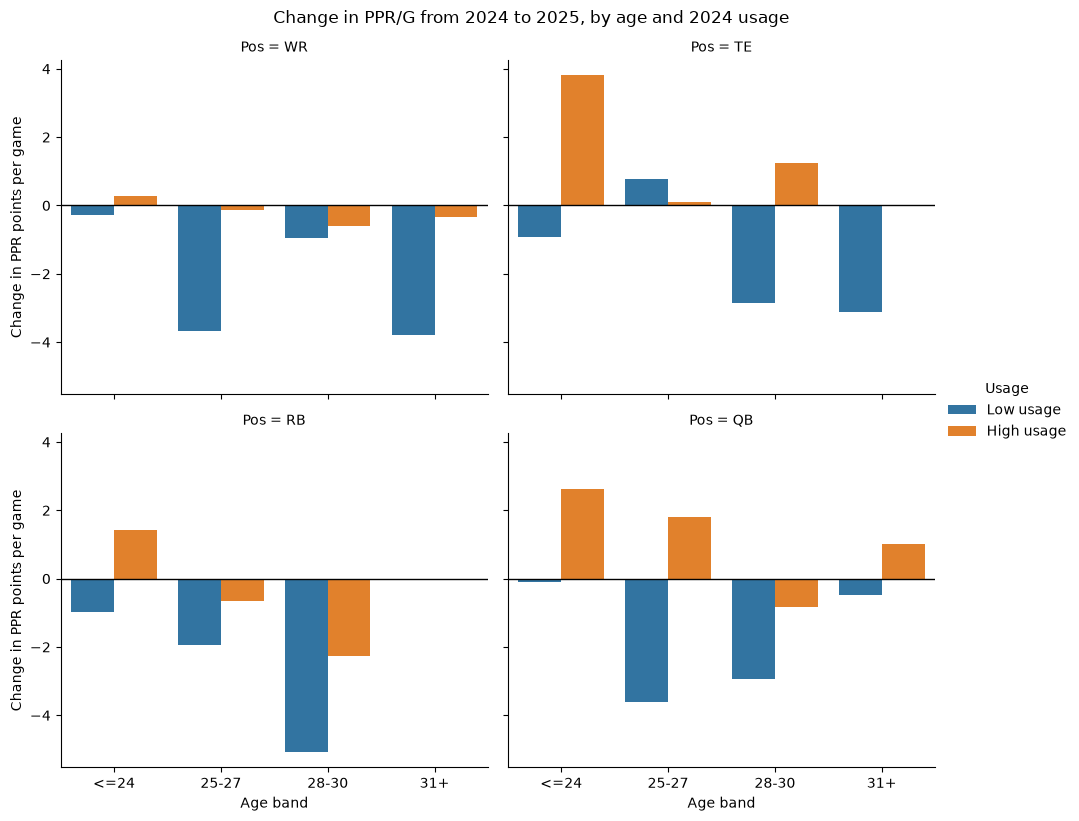

Age band        <=24  25-27  28-30  31+
Pos Usage                              
QB  Low usage      3      7      2    3
    High usage     4      4      3    3
RB  Low usage      6     11      1    0
    High usage     6      8      4    0
TE  Low usage      5      6      3    0
    High usage     1      4      5    4
WR  Low usage     13      5      2    2
    High usage     8      9      2    3

In [10]:
age0 = qual[qual['year'] == y0].set_index('Player')['Age']

change = pd.DataFrame({
    'Pos': nxt['Pos'],
    'Age': age0.reindex(nxt.index),
    'PlaysPG': nxt[('PlaysPG', y0)],
    'PPR/G change': nxt[('FantasyPPRPerGame', y1)] - nxt[('FantasyPPRPerGame', y0)],
}).dropna()

# High vs low usage = above/below the median plays per game within the same position
change['Usage'] = (change.groupby('Pos')['PlaysPG']
                         .transform(lambda s: pd.qcut(s.rank(method='first'), 2, labels=['Low usage', 'High usage'])))

bands = [0, 24, 27, 30, 50]
labels = ['<=24', '25-27', '28-30', '31+']
change['Age band'] = pd.cut(change['Age'], bins=bands, labels=labels)

g = sns.catplot(data=change, x='Age band', y='PPR/G change', hue='Usage', col='Pos',
                kind='bar', errorbar=None, col_wrap=2, height=4, aspect=1.2,
                hue_order=['Low usage', 'High usage'])
for ax in g.axes.flat:
    ax.axhline(0, color='black', linewidth=1)
g.set_axis_labels('Age band', 'Change in PPR points per game')
g.figure.suptitle(f'Change in PPR/G from {y0} to {y1}, by age and {y0} usage', y=1.02)
plt.show()

# Sample sizes behind each bar
change.groupby(['Pos', 'Usage', 'Age band'], observed=True).size().unstack(fill_value=0)

In [11]:
rb = qual[qual['Pos'] == 'RB'].copy()
rb['YPC'] = rb['RushYds'] / rb['RushAtt'].replace(0, np.nan)
w = rb.pivot_table(index='Player', columns='year',
                   values=['RushAttPG', 'YPC', 'FantasyPPRPerGame']).dropna()
age_rb = rb[rb['year'] == y0].set_index('Player')['Age']

out = pd.DataFrame({
    'Age': age_rb.reindex(w.index),
    'Carries/G change': w[('RushAttPG', y1)] - w[('RushAttPG', y0)],
    'YPC change': w[('YPC', y1)] - w[('YPC', y0)],
    'PPR/G change': w[('FantasyPPRPerGame', y1)] - w[('FantasyPPRPerGame', y0)],
}).dropna()
out['Age band'] = pd.cut(out['Age'], bins=[0, 24, 27, 30, 50], labels=['<=24', '25-27', '28-30', '31+'])

out.groupby('Age band', observed=True).agg(
    n=('PPR/G change', 'size'),
    carries=('Carries/G change', 'mean'),
    ypc=('YPC change', 'mean'),
    ppr=('PPR/G change', 'mean'),
).round(2)

,n,carries,ypc,ppr
Age band,,,,
<=24,12,1.06,0.06,0.22
25-27,19,-1.24,-0.02,-1.19
28-30,5,-3.97,-0.12,-4.52


In [12]:
rows = []
for pos, g in nxt.groupby('Pos'):
    rows.append({
        'Pos': pos,
        'n': len(g),
        'PlaysPG persistence': g[('PlaysPG', y0)].corr(g[('PlaysPG', y1)]),
        'PPR/G persistence': g[('FantasyPPRPerGame', y0)].corr(g[('FantasyPPRPerGame', y1)]),
    })
pd.DataFrame(rows).set_index('Pos').round(2)

,n,PlaysPG persistence,PPR/G persistence
Pos,,,
QB,29,0.30,0.40
RB,36,0.60,0.65
TE,28,0.48,0.30
WR,44,0.70,0.64


In [22]:
ip = get_ipython()

print("Kernel available:", ip is not None)
print("History entries:", len(ip.user_ns.get("In", [])))

for i, cell in enumerate(ip.user_ns.get("In", [])):
    if any(term in cell.lower() for term in [
        "kmeans", "cluster", "standardscaler", "fantasypprpergame"
    ]):
        print(f"\n--- EXECUTED CELL {i} ---")
        print(cell[:1500])

Kernel available: True
History entries: 23

--- EXECUTED CELL 4 ---
features = ['GS', 'Plays', 'RushAtt', 'RushYds', 'RushTD', 'Tgt', 'Rec', 'ReceiveYds', 'ReceiveTD',
            'PassAtt', 'PassYds', 'PassTD', 'Int']
by_pos = pd.DataFrame({
    pos: g[features].corrwith(g['FantasyPPRPerGame']) for pos, g in df.groupby('Pos')
})
plt.figure(figsize=(7, 7))
sns.heatmap(by_pos, annot=True, fmt='.2f', cmap='coolwarm', center=0, linewidths=.5)
plt.title('Correlation with FantasyPPRPerGame, within each position')
plt.tight_layout()
plt.show()

--- EXECUTED CELL 5 ---
def cv_r2(X, y, k=5, reps=30, seed=0):
    X = np.asarray(X, float)
    if X.ndim == 1:
        X = X[:, None]
    y = np.asarray(y, float)
    n = len(y)
    rng = np.random.default_rng(seed)
    scores = []
    for _ in range(reps):
        idx = rng.permutation(n)
        pred = np.empty(n)
        for f in np.array_split(idx, k):
            tr = np.setdiff1d(idx, f)
            A = np.column_stack([np.ones(len(tr)), X[tr]]

In [23]:
from pathlib import Path

history = get_ipython().user_ns.get("In", [])

recovery_path = Path.home() / "Desktop/RECOVERED_KMEANS_HISTORY.py"

with recovery_path.open("w", encoding="utf-8") as f:
    for i, cell in enumerate(history):
        f.write(f"\n\n# ===== EXECUTED CELL {i} =====\n\n")
        f.write(cell)
        f.write("\n")

print("Recovery saved to:", recovery_path)
print("Cells recovered:", len(history))

Recovery saved to: /Users/nathanyoung/Desktop/RECOVERED_KMEANS_HISTORY.py
Cells recovered: 24


In [24]:
from pathlib import Path

history = get_ipython().user_ns.get("In", [])

recovery_path = Path.home() / "Desktop/RECOVERED_KMEANS_HISTORY.py"

with recovery_path.open("w", encoding="utf-8") as f:
    for i, cell in enumerate(history):
        f.write(f"\n\n# ===== EXECUTED CELL {i} =====\n\n")
        f.write(cell)
        f.write("\n")

print("Recovery saved to:", recovery_path)
print("Cells recovered:", len(history))

s = recovery_path.read_text()

for term in ["KMeans", "n_clusters", "clustered_df", "cluster_summary", "StandardScaler"]:
    print(f"{term}: {term.lower() in s.lower()}")

Recovery saved to: /Users/nathanyoung/Desktop/RECOVERED_KMEANS_HISTORY.py
Cells recovered: 25
KMeans: True
n_clusters: True
clustered_df: True
cluster_summary: True
StandardScaler: True
